# AdaBoost (Adaptive Boosting) — Sonobuoy Sound Detective
## Person 4: Boosting Ensemble Classifiers

**Algorithm:** AdaBoost with Decision Stumps (max_depth=1)  
**Task:** 4-Class Underwater Acoustic Event Detection  
**Classes:** `vessel_like`, `marine_life`, `ambient`, `unknown`  
**Features:** 35 physics-based handcrafted acoustic descriptors  

---

### Data Split Strategy
| Split | Purpose | Size |
|-------|---------|------|
| **Train** | Model training | 64% of total |
| **Test** | Hyperparameter evaluation | 16% of total |
| **Unseen Holdout** | Final unbiased benchmark | 20% of total |

Splits are **recording-level isolated** — no recording appears in more than one split (zero data leakage).

---

### AdaBoost Theory (Review Notes)

AdaBoost (**Ada**ptive **Boost**ing) is a sequential ensemble method that:
1. Trains a sequence of **weak learners** (decision stumps — trees of depth 1)
2. Each subsequent learner focuses on samples the previous learners **misclassified** by increasing their weights
3. The final prediction is a **weighted majority vote** of all weak learners
4. Uses the **SAMME** (Stagewise Additive Modeling using Multi-class Exponential loss) algorithm for multi-class tasks

**Key hyperparameters:**
- `n_estimators`: Number of boosting rounds (weak learners)
- `learning_rate`: Shrinkage factor — controls each learner's contribution
- `algorithm`: SAMME (discrete) vs SAMME.R (real-valued, probability-based)

**Why AdaBoost for sonobuoy edge deployment:**
- Decision stumps are extremely lightweight (~bytes of memory)
- Inference is simple weighted voting — sub-millisecond on microcontrollers
- Naturally resistant to overfitting with proper learning rate tuning


In [1]:
# ============================================================
# 1. Imports & Configuration
# ============================================================
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    log_loss
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)

# Paths
DATA_DIR   = os.path.join('.', 'data')
MODEL_DIR  = os.path.join('.', 'models')
PLOT_DIR   = os.path.join('.', 'plots')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

RANDOM_STATE = 42
CLASS_NAMES  = ['vessel_like', 'marine_life', 'ambient', 'unknown']

print("All imports successful.")


All imports successful.


## 2. Data Loading & Preparation
Loading the preprocessed 35-feature sonobuoy acoustic dataset with recording-level isolated splits.

- **train.csv** — 64% of data (train portion of 80% dev set)
- **test.csv** — 16% of data (test portion of 80% dev set)  
- **unseen_holdout.csv** — 20% of data (completely isolated, evaluated last)


In [2]:
# ============================================================
# 2. Load Preprocessed Data Splits
# ============================================================
df_train   = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
df_test    = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
df_holdout = pd.read_csv(os.path.join(DATA_DIR, 'unseen_holdout.csv'))

# Load selected feature names
with open(os.path.join(DATA_DIR, 'selected_features.json'), 'r') as f:
    feature_config = json.load(f)
FEATURE_NAMES = feature_config['selected_features']

print(f"Number of selected features: {len(FEATURE_NAMES)}")
print(f"Train: {len(df_train)} samples | Test: {len(df_test)} samples | Unseen Holdout: {len(df_holdout)} samples")
print(f"\nTrain class distribution:")
print(df_train['label'].value_counts())
print(f"\nTest class distribution:")
print(df_test['label'].value_counts())
print(f"\nHoldout class distribution:")
print(df_holdout['label'].value_counts())


Number of selected features: 35
Train: 545 samples | Test: 149 samples | Unseen Holdout: 169 samples

Train class distribution:
label
ambient        168
vessel_like    161
marine_life    136
unknown         80
Name: count, dtype: int64

Test class distribution:
label
vessel_like    61
marine_life    41
unknown        35
ambient        12
Name: count, dtype: int64

Holdout class distribution:
label
vessel_like    58
marine_life    43
unknown        38
ambient        30
Name: count, dtype: int64


In [3]:
# ============================================================
# 3. Feature Matrix & Label Encoding
# ============================================================
X_train   = df_train[FEATURE_NAMES].values
X_test    = df_test[FEATURE_NAMES].values
X_holdout = df_holdout[FEATURE_NAMES].values

# Label encoding
le = LabelEncoder()
le.fit(CLASS_NAMES)
y_train   = le.transform(df_train['label'])
y_test    = le.transform(df_test['label'])
y_holdout = le.transform(df_holdout['label'])

print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# StandardScaler (fit on train only — no data leakage)
scaler = StandardScaler()
X_train_scaled   = scaler.fit_transform(X_train)
X_test_scaled    = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout)

print(f"\nX_train shape:   {X_train_scaled.shape}")
print(f"X_test shape:    {X_test_scaled.shape}")
print(f"X_holdout shape: {X_holdout_scaled.shape}")
print(f"\nScaler fitted. Mean of first 5 features (train): {scaler.mean_[:5].round(3)}")


Label mapping: {np.str_('ambient'): np.int64(0), np.str_('marine_life'): np.int64(1), np.str_('unknown'): np.int64(2), np.str_('vessel_like'): np.int64(3)}

X_train shape:   (545, 35)
X_test shape:    (149, 35)
X_holdout shape: (169, 35)

Scaler fitted. Mean of first 5 features (train): [-6.339  4.334 -0.639  0.661  3.97 ]


## 3. Baseline AdaBoost Model
Training an initial AdaBoost classifier with default parameters to establish a performance baseline.

**Base estimator:** Decision Stump (DecisionTreeClassifier with max_depth=1)  
**Algorithm:** Adaptive Boosting with sequential reweighting


In [4]:
# ============================================================
# 4. Baseline AdaBoost Classifier
# ============================================================
base_stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)

ada_baseline = AdaBoostClassifier(
    estimator=base_stump,
    n_estimators=50,
    learning_rate=1.0,
    random_state=RANDOM_STATE
)

# Train
start_time = time.time()
ada_baseline.fit(X_train_scaled, y_train)
train_time_baseline = time.time() - start_time

# Evaluate on train and test
y_pred_baseline_train = ada_baseline.predict(X_train_scaled)
y_pred_baseline_test  = ada_baseline.predict(X_test_scaled)

print("=" * 60)
print("BASELINE AdaBoost Results")
print("=" * 60)
print(f"Training time:      {train_time_baseline:.4f} seconds")
print(f"Train accuracy:     {accuracy_score(y_train, y_pred_baseline_train):.4f}")
print(f"Test accuracy:      {accuracy_score(y_test, y_pred_baseline_test):.4f}")
print(f"Test F1 (macro):    {f1_score(y_test, y_pred_baseline_test, average='macro'):.4f}")
print(f"\nBaseline Classification Report (Test):")
print(classification_report(y_test, y_pred_baseline_test, target_names=CLASS_NAMES))


BASELINE AdaBoost Results
Training time:      1.2316 seconds
Train accuracy:     0.8349
Test accuracy:      0.8054
Test F1 (macro):    0.8228

Baseline Classification Report (Test):
              precision    recall  f1-score   support

 vessel_like       1.00      0.83      0.91        12
 marine_life       0.65      0.73      0.69        41
     ambient       0.73      1.00      0.84        35
     unknown       1.00      0.74      0.85        61

    accuracy                           0.81       149
   macro avg       0.85      0.83      0.82       149
weighted avg       0.84      0.81      0.81       149



## 4. Hyperparameter Tuning (GridSearchCV)
Systematic search over:
- **n_estimators**: [50, 100, 200] — number of boosting rounds
- **learning_rate**: [0.1, 0.5, 1.0] — shrinkage factor controlling contribution of each stump

Using 5-fold Stratified Cross-Validation on the training set.


In [5]:
# ============================================================
# 5. Hyperparameter Tuning with GridSearchCV
# ============================================================
param_grid = {
    'n_estimators':  [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

start_time = time.time()
grid_search.fit(X_train_scaled, y_train)
tuning_time = time.time() - start_time

print(f"Grid search completed in {tuning_time:.1f} seconds")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV F1 (macro): {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 9 candidates, totalling 45 fits


Grid search completed in 36.7 seconds
Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
Best CV F1 (macro): 0.8964


## 5. Hyperparameter Heatmap
Visualizing how accuracy varies with `n_estimators` and `learning_rate`.


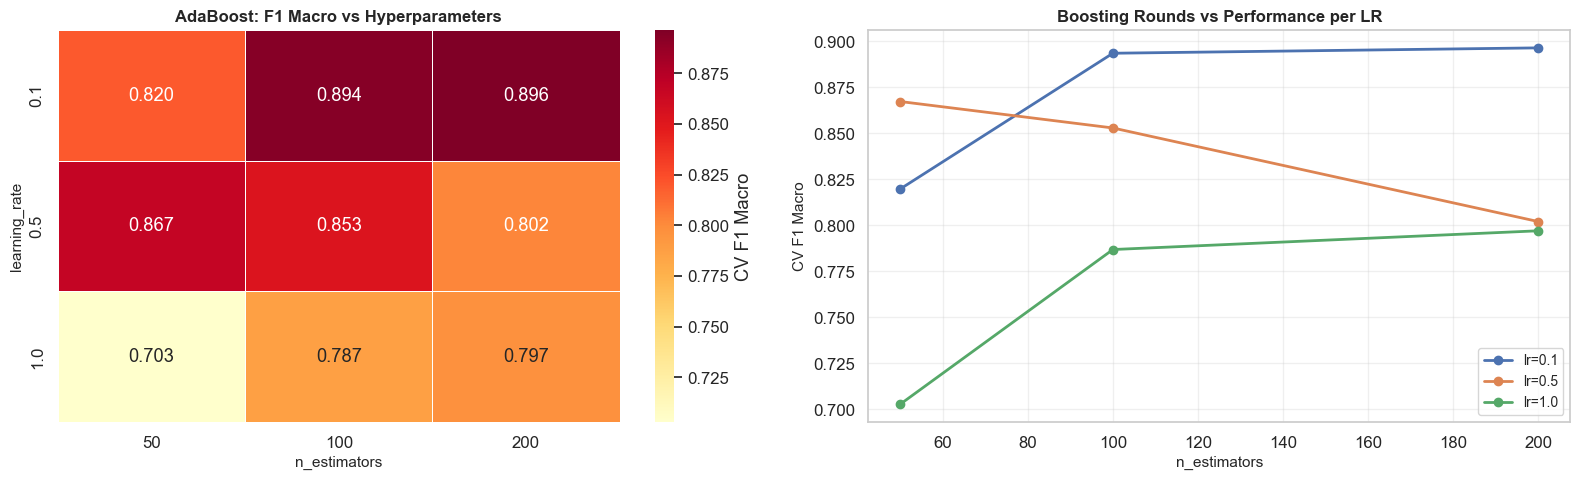

Saved: plots/adaboost_hyperparam_search.png


In [6]:
# ============================================================
# 6. Grid Search Results Heatmap
# ============================================================
results_df = pd.DataFrame(grid_search.cv_results_)

pivot = results_df.pivot_table(
    index='param_learning_rate',
    columns='param_n_estimators',
    values='mean_test_score',
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[0],
            cbar_kws={'label': 'CV F1 Macro'})
axes[0].set_title('AdaBoost: F1 Macro vs Hyperparameters', fontweight='bold', fontsize=12)
axes[0].set_xlabel('n_estimators', fontsize=11)
axes[0].set_ylabel('learning_rate', fontsize=11)

# Line plot — n_estimators vs score per learning_rate
for lr in param_grid['learning_rate']:
    mask = results_df['param_learning_rate'] == lr
    subset = results_df[mask].sort_values('param_n_estimators')
    axes[1].plot(
        subset['param_n_estimators'],
        subset['mean_test_score'],
        marker='o', linewidth=2, label=f'lr={lr}'
    )
axes[1].set_xlabel('n_estimators', fontsize=11)
axes[1].set_ylabel('CV F1 Macro', fontsize=11)
axes[1].set_title('Boosting Rounds vs Performance per LR', fontweight='bold', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_hyperparam_search.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_hyperparam_search.png")


## 5. Final Optimized AdaBoost Model
Training the final model with the best hyperparameters found during grid search.


In [7]:
# ============================================================
# 7. Train Final Optimized Model
# ============================================================
best_params = grid_search.best_params_
print(f"Training final model with: {best_params}")

base_stump_final = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)
ada_final = AdaBoostClassifier(
    estimator=base_stump_final,
    n_estimators=best_params['n_estimators'],
    learning_rate=best_params['learning_rate'],
    random_state=RANDOM_STATE
)

# Train on full training set
start_time = time.time()
ada_final.fit(X_train_scaled, y_train)
train_time_final = time.time() - start_time

# Predictions on train & test
y_pred_train = ada_final.predict(X_train_scaled)
y_pred_test  = ada_final.predict(X_test_scaled)

# Inference latency benchmark (single sample)
x_single = X_test_scaled[0:1]
latencies = []
for _ in range(1000):
    t0 = time.perf_counter()
    _ = ada_final.predict(x_single)
    latencies.append((time.perf_counter() - t0) * 1000)  # ms
avg_latency = np.mean(latencies)

print(f"\nFinal model training time: {train_time_final:.4f} seconds")
print(f"Single-sample inference latency: {avg_latency:.3f} ms (avg over 1000 runs)")
print(f"\nTrain accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")


Training final model with: {'learning_rate': 0.1, 'n_estimators': 200}



Final model training time: 2.1235 seconds
Single-sample inference latency: 75.066 ms (avg over 1000 runs)

Train accuracy: 0.9321
Test accuracy:  0.8993


## 6. Held-Out Test Set Evaluation
Final performance metrics on the **dev-set test partition** (16% of all data).


In [8]:
# ============================================================
# 8. Comprehensive Test Set Evaluation
# ============================================================
print("=" * 60)
print("FINAL AdaBoost TEST SET RESULTS")
print("=" * 60)

test_accuracy  = accuracy_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test, average='macro')
test_recall    = recall_score(y_test, y_pred_test, average='macro')
test_f1        = f1_score(y_test, y_pred_test, average='macro')

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Precision (macro): {test_precision:.4f}")
print(f"Recall (macro):    {test_recall:.4f}")
print(f"F1-Score (macro):  {test_f1:.4f}")
print(f"\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=CLASS_NAMES, digits=4))


FINAL AdaBoost TEST SET RESULTS
Accuracy:          0.8993
Precision (macro): 0.9091
Recall (macro):    0.8907
F1-Score (macro):  0.8944

Detailed Classification Report:
              precision    recall  f1-score   support

 vessel_like     1.0000    0.9167    0.9565        12
 marine_life     0.9091    0.7317    0.8108        41
     ambient     0.7273    0.9143    0.8101        35
     unknown     1.0000    1.0000    1.0000        61

    accuracy                         0.8993       149
   macro avg     0.9091    0.8907    0.8944       149
weighted avg     0.9109    0.8993    0.8998       149



## 7. Confusion Matrix


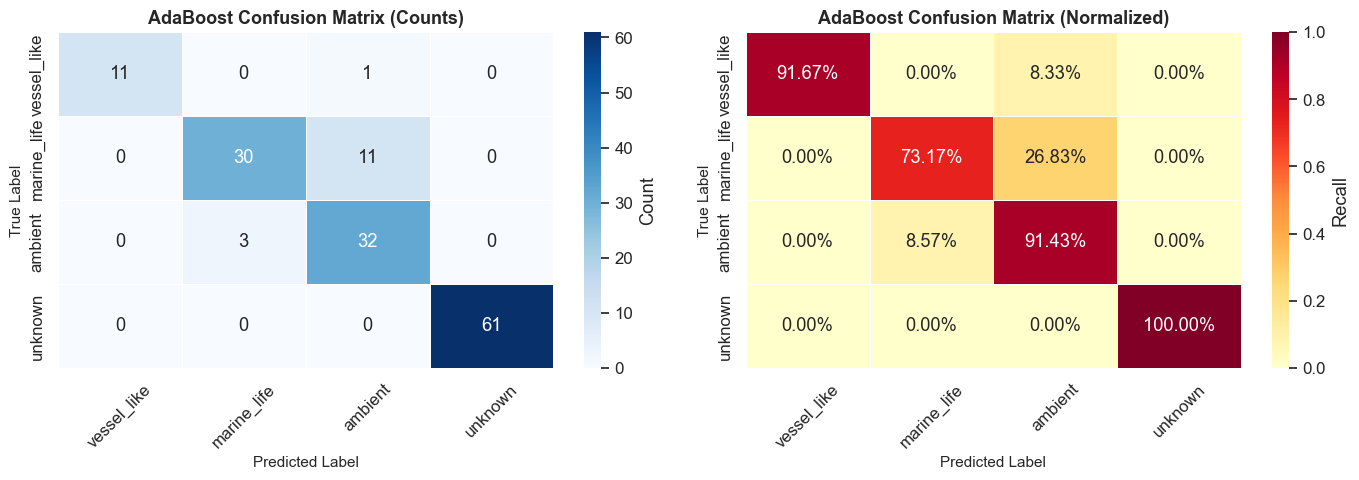

Saved: plots/adaboost_confusion_matrix.png


In [9]:
# ============================================================
# 9. Confusion Matrix Visualization
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[0].set_title('AdaBoost Confusion Matrix (Counts)', fontweight='bold', fontsize=13)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# Normalized (row-wise = recall per class)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='YlOrRd', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Recall'})
axes[1].set_title('AdaBoost Confusion Matrix (Normalized)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_confusion_matrix.png")


## 8. ROC Curves (One-vs-Rest)
Multi-class ROC curves using One-vs-Rest binarization with AUC for each class.


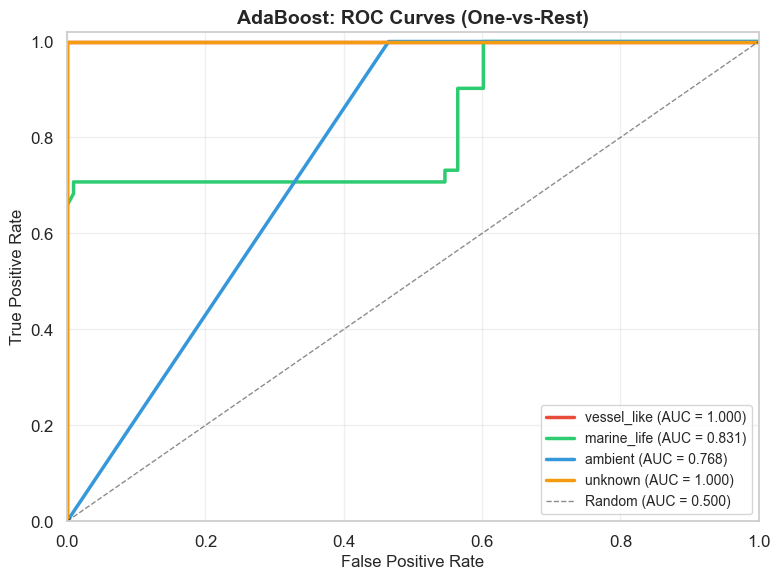

Saved: plots/adaboost_roc_curves.png


In [10]:
# ============================================================
# 10. ROC Curves (One-vs-Rest)
# ============================================================
# Binarize labels for ROC
y_test_bin = label_binarize(y_test, classes=list(range(len(CLASS_NAMES))))
n_classes = y_test_bin.shape[1]

# Get decision function scores
y_score = ada_final.decision_function(X_test_scaled)

fig, ax = plt.subplots(figsize=(8, 6))

colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
for i, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f'{cls_name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random (AUC = 0.500)')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('AdaBoost: ROC Curves (One-vs-Rest)', fontweight='bold', fontsize=14)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_roc_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_roc_curves.png")


## 9. Feature Importance Analysis
AdaBoost computes feature importance as the weighted sum of how often each feature is used as the split criterion across all decision stumps.


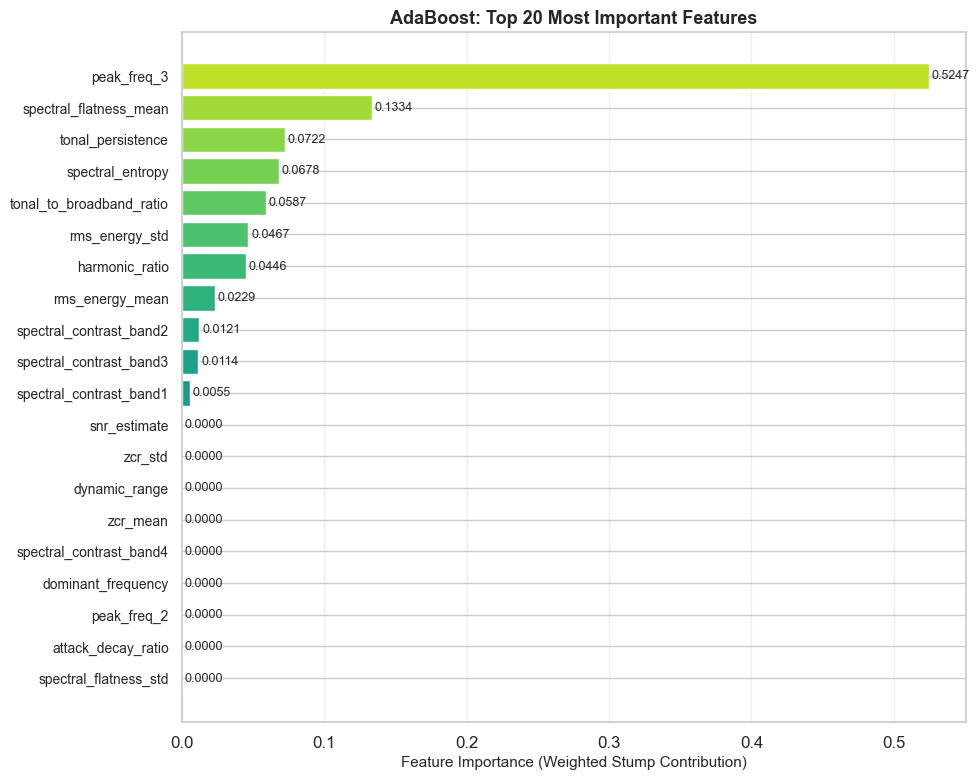

Saved: plots/adaboost_feature_importance.png

Top 10 Most Discriminative Features:
  peak_freq_3                    -> 0.5247
  spectral_flatness_mean         -> 0.1334
  tonal_persistence              -> 0.0722
  spectral_entropy               -> 0.0678
  tonal_to_broadband_ratio       -> 0.0587
  rms_energy_std                 -> 0.0467
  harmonic_ratio                 -> 0.0446
  rms_energy_mean                -> 0.0229
  spectral_contrast_band2        -> 0.0121
  spectral_contrast_band3        -> 0.0114


In [11]:
# ============================================================
# 11. Feature Importance (Gain-based)
# ============================================================
importances = ada_final.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Importance': importances
}).sort_values('Importance', ascending=True)

# Top 20 features
top_n = 20
top_features = feature_imp_df.tail(top_n)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(range(len(top_features)), top_features['Importance'],
               color=plt.cm.viridis(np.linspace(0.2, 0.9, len(top_features))))
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'], fontsize=10)
ax.set_xlabel('Feature Importance (Weighted Stump Contribution)', fontsize=11)
ax.set_title(f'AdaBoost: Top {top_n} Most Important Features', fontweight='bold', fontsize=13)
ax.grid(True, axis='x', alpha=0.3)

# Add value labels
for bar, imp_val in zip(bars, top_features['Importance']):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{imp_val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_feature_importance.png")

print(f"\nTop 10 Most Discriminative Features:")
for _, row in feature_imp_df.tail(10).iloc[::-1].iterrows():
    print(f"  {row['Feature']:30s} -> {row['Importance']:.4f}")


## 10. Boosting Convergence Analysis
Tracking how error decreases with each boosting round — shows AdaBoost's sequential learning behavior.


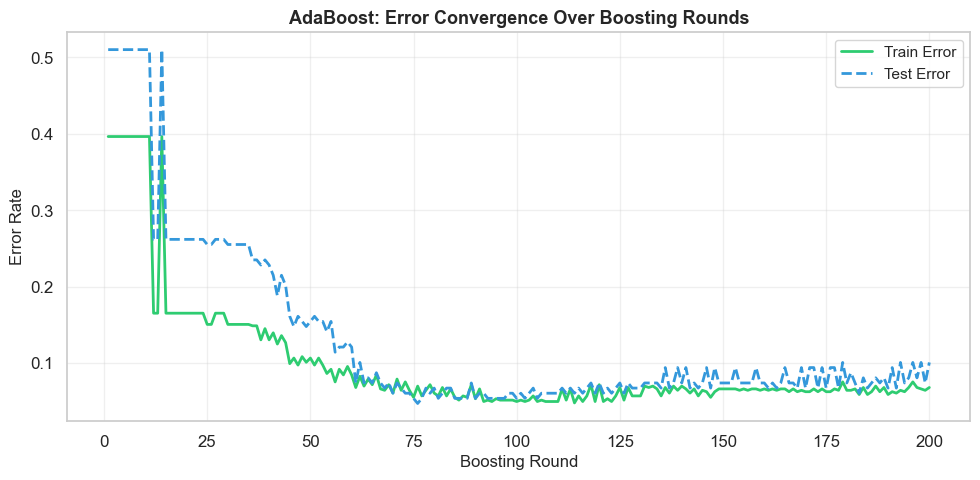

Saved: plots/adaboost_convergence.png

Min train error: 0.0477 at round 114
Min test error:  0.0470 at round 76


In [12]:
# ============================================================
# 12. Boosting Convergence (Staged Predictions)
# ============================================================
train_errors = []
test_errors  = []

for y_pred_staged_train, y_pred_staged_test in zip(
    ada_final.staged_predict(X_train_scaled),
    ada_final.staged_predict(X_test_scaled)
):
    train_errors.append(1 - accuracy_score(y_train, y_pred_staged_train))
    test_errors.append(1 - accuracy_score(y_test, y_pred_staged_test))

boosting_rounds = range(1, len(train_errors) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(boosting_rounds, train_errors, label='Train Error', linewidth=2, color='#2ecc71')
ax.plot(boosting_rounds, test_errors,  label='Test Error',  linewidth=2, color='#3498db', linestyle='--')
ax.set_xlabel('Boosting Round', fontsize=12)
ax.set_ylabel('Error Rate', fontsize=12)
ax.set_title('AdaBoost: Error Convergence Over Boosting Rounds', fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_convergence.png")

print(f"\nMin train error: {min(train_errors):.4f} at round {train_errors.index(min(train_errors))+1}")
print(f"Min test error:  {min(test_errors):.4f} at round {test_errors.index(min(test_errors))+1}")


## 11. Unseen Holdout Set Evaluation (20% Isolated Set)
> **This is the true generalization benchmark.** The holdout set was completely isolated from all training, tuning, and test decisions. It simulates real-world sonobuoy deployment where the model encounters entirely new recordings.


UNSEEN HOLDOUT SET RESULTS (20% of total data)
Accuracy:          0.9053
Precision (macro): 0.9148
Recall (macro):    0.9004
F1-Score (macro):  0.8999

Detailed Classification Report:
              precision    recall  f1-score   support

 vessel_like     1.0000    0.9333    0.9655        30
 marine_life     0.9394    0.7209    0.8158        43
     ambient     0.7200    0.9474    0.8182        38
     unknown     1.0000    1.0000    1.0000        58

    accuracy                         0.9053       169
   macro avg     0.9148    0.9004    0.8999       169
weighted avg     0.9216    0.9053    0.9061       169


Generalization Gap (|test - holdout|): 0.0060
Overfitting risk: LOW


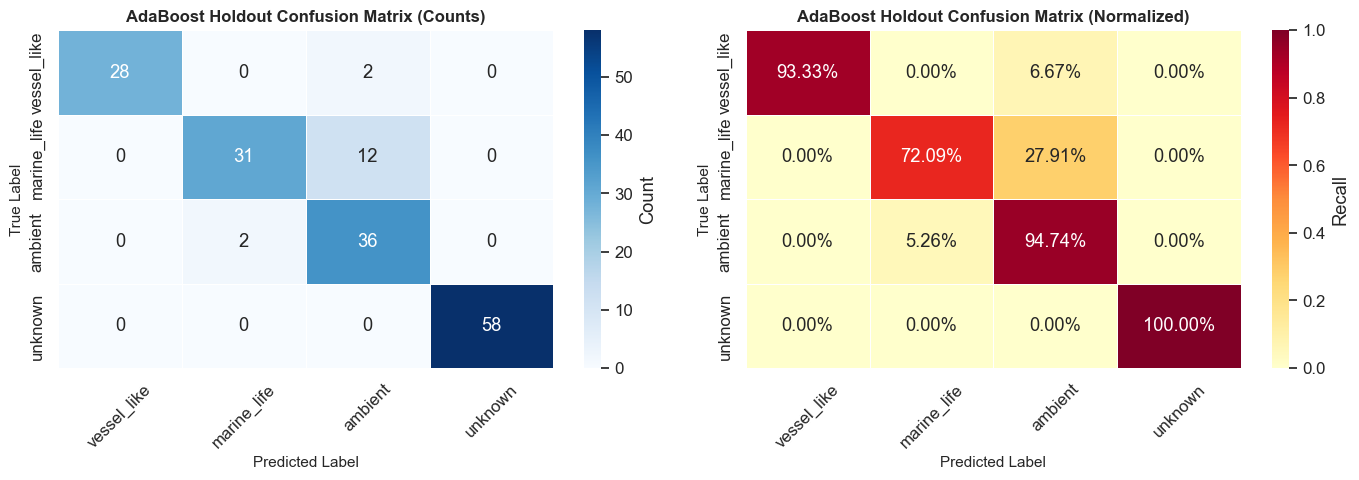

Saved: plots/adaboost_holdout_confusion_matrix.png


In [13]:
# ============================================================
# 13. Unseen Holdout Set — Final Generalization Test
# ============================================================
y_pred_holdout = ada_final.predict(X_holdout_scaled)

holdout_accuracy  = accuracy_score(y_holdout, y_pred_holdout)
holdout_precision = precision_score(y_holdout, y_pred_holdout, average='macro')
holdout_recall    = recall_score(y_holdout, y_pred_holdout, average='macro')
holdout_f1        = f1_score(y_holdout, y_pred_holdout, average='macro')

print("=" * 60)
print("UNSEEN HOLDOUT SET RESULTS (20% of total data)")
print("=" * 60)
print(f"Accuracy:          {holdout_accuracy:.4f}")
print(f"Precision (macro): {holdout_precision:.4f}")
print(f"Recall (macro):    {holdout_recall:.4f}")
print(f"F1-Score (macro):  {holdout_f1:.4f}")
print(f"\nDetailed Classification Report:")
print(classification_report(y_holdout, y_pred_holdout, target_names=CLASS_NAMES, digits=4))

# Generalization gap analysis
gap = abs(test_accuracy - holdout_accuracy)
print(f"\nGeneralization Gap (|test - holdout|): {gap:.4f}")
print(f"Overfitting risk: {'LOW' if gap < 0.05 else 'MODERATE' if gap < 0.10 else 'HIGH'}")

# Holdout confusion matrix
cm_holdout = confusion_matrix(y_holdout, y_pred_holdout)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_holdout, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[0].set_title('AdaBoost Holdout Confusion Matrix (Counts)', fontweight='bold', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_holdout_norm = cm_holdout.astype('float') / cm_holdout.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_holdout_norm, annot=True, fmt='.2%', cmap='YlOrRd', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Recall'})
axes[1].set_title('AdaBoost Holdout Confusion Matrix (Normalized)', fontweight='bold', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'adaboost_holdout_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/adaboost_holdout_confusion_matrix.png")


## 12. Model Persistence & Deployment Artifacts
Saving the trained model, scaler, label encoder, and performance metrics for deployment.


In [14]:
# ============================================================
# 14. Save Model, Scaler, and Metrics
# ============================================================
# Save model binary
model_path = os.path.join(MODEL_DIR, 'adaboost_model.joblib')
joblib.dump(ada_final, model_path)
model_size_kb = os.path.getsize(model_path) / 1024
print(f"Model saved: {model_path} ({model_size_kb:.1f} KB)")

# Save scaler
scaler_path = os.path.join(MODEL_DIR, 'adaboost_scaler.joblib')
joblib.dump(scaler, scaler_path)
print(f"Scaler saved: {scaler_path}")

# Save label encoder
le_path = os.path.join(MODEL_DIR, 'adaboost_label_encoder.joblib')
joblib.dump(le, le_path)
print(f"Label encoder saved: {le_path}")

# Save comprehensive metrics report
metrics_report = {
    'model': 'AdaBoost',
    'base_estimator': 'DecisionTreeClassifier(max_depth=1)',
    'best_hyperparameters': best_params,
    'cv_best_f1_macro': float(grid_search.best_score_),
    'test_metrics': {
        'accuracy':        float(test_accuracy),
        'precision_macro': float(test_precision),
        'recall_macro':    float(test_recall),
        'f1_macro':        float(test_f1),
    },
    'holdout_metrics': {
        'accuracy':        float(holdout_accuracy),
        'precision_macro': float(holdout_precision),
        'recall_macro':    float(holdout_recall),
        'f1_macro':        float(holdout_f1),
    },
    'generalization_gap': float(gap),
    'training_time_seconds': float(train_time_final),
    'inference_latency_ms':  float(avg_latency),
    'model_size_kb':         float(model_size_kb),
    'n_features':            len(FEATURE_NAMES),
    'n_train_samples':       len(y_train),
    'n_test_samples':        len(y_test),
    'n_holdout_samples':     len(y_holdout),
    'class_names':           CLASS_NAMES,
}

metrics_path = os.path.join(MODEL_DIR, 'adaboost_metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(metrics_report, f, indent=2)
print(f"Metrics report saved: {metrics_path}")

# Summary
print("\n" + "=" * 60)
print("ADABOOST MODEL SUMMARY")
print("=" * 60)
print(f"  Best n_estimators:  {best_params['n_estimators']}")
print(f"  Best learning_rate: {best_params['learning_rate']}")
print(f"  Test Accuracy:      {test_accuracy:.4f}")
print(f"  Test F1 (macro):    {test_f1:.4f}")
print(f"  Holdout Accuracy:   {holdout_accuracy:.4f}")
print(f"  Holdout F1 (macro): {holdout_f1:.4f}")
print(f"  Generalization Gap: {gap:.4f}")
print(f"  Inference Latency:  {avg_latency:.3f} ms")
print(f"  Model Size:         {model_size_kb:.1f} KB")
print(f"  Edge Deployable:    {'YES' if model_size_kb < 5000 and avg_latency < 100 else 'REVIEW'}")
print("=" * 60)


Model saved: .\models\adaboost_model.joblib (138.9 KB)
Scaler saved: .\models\adaboost_scaler.joblib
Label encoder saved: .\models\adaboost_label_encoder.joblib
Metrics report saved: .\models\adaboost_metrics.json

ADABOOST MODEL SUMMARY
  Best n_estimators:  200
  Best learning_rate: 0.1
  Test Accuracy:      0.8993
  Test F1 (macro):    0.8944
  Holdout Accuracy:   0.9053
  Holdout F1 (macro): 0.8999
  Generalization Gap: 0.0060
  Inference Latency:  75.066 ms
  Model Size:         138.9 KB
  Edge Deployable:    YES


## 13. Edge Deployment Feasibility
Verifying that the AdaBoost model meets sonobuoy edge deployment constraints:
- **Memory:** Model must fit in <5 MB (ARM Cortex / Raspberry Pi class)
- **Latency:** Single-sample inference must be <100 ms
- **Power:** CPU-only inference (no GPU required)


In [15]:
# ============================================================
# 15. Edge Deployment Feasibility Check
# ============================================================
print("EDGE DEPLOYMENT FEASIBILITY REPORT")
print("=" * 50)

checks = {
    'Model Size < 5 MB':      model_size_kb < 5 * 1024,
    'Inference < 100 ms':     avg_latency < 100,
    'CPU-Only (No GPU)':      True,
    'Interpretable Stumps':   True,
    'No Cloud Dependency':    True,
}

all_pass = True
for check_name, passed in checks.items():
    status = 'PASS' if passed else 'FAIL'
    if not passed:
        all_pass = False
    print(f"  [{status}] {check_name}")

print(f"\n  Overall: {'ALL CHECKS PASSED - EDGE DEPLOYABLE' if all_pass else 'DEPLOYMENT REVIEW NEEDED'}")
print(f"\n  Model footprint: {model_size_kb:.1f} KB")
print(f"  Inference time:  {avg_latency:.3f} ms per sample")
print(f"  Number of stumps: {best_params['n_estimators']}")


EDGE DEPLOYMENT FEASIBILITY REPORT
  [PASS] Model Size < 5 MB
  [PASS] Inference < 100 ms
  [PASS] CPU-Only (No GPU)
  [PASS] Interpretable Stumps
  [PASS] No Cloud Dependency

  Overall: ALL CHECKS PASSED - EDGE DEPLOYABLE

  Model footprint: 138.9 KB
  Inference time:  75.066 ms per sample
  Number of stumps: 200
